# Credit Default Prediction with Machine Learning

**Project notebook — four-week workflow**

This notebook follows the four milestones in the LAB 4 project instructions: (1) project definition and exploratory data analysis, (2) data preparation and baseline, (3) model development and experimentation, and (4) final evaluation and presentation. All deliverables are written in English.

**Team members:** [Add the names of the 2–4 group members before submission]

**Research question:** Can client repayment history and credit profile variables in the UCI Default of Credit Card Clients dataset predict whether a client will default on the next month's payment?

**Scope:** This is an educational, retrospective binary-classification study. The model is not intended to make real lending decisions.

## Week 1 — Project definition and data collection

### Problem and relevance
Credit default creates losses for lenders and affects portfolio risk. The project tests whether a supervised classification model can identify elevated next-month default risk from the client's recorded credit limit, demographic profile, repayment status and payment history. The target is the dataset's default payment next month label (1 = default, 0 = no default).

### Dataset and source
We use the locally supplied UCI Default of Credit Card Clients spreadsheet (data/default of credit card clients.xls). The public dataset page is [UCI Machine Learning Repository, dataset 350](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). The commonly distributed version contains 30,000 client records, 23 explanatory variables and one binary target. Its size, labelled outcomes and financial-risk context make it suitable for a compact supervised-learning project. We verify these details from the actual file below. The dataset is historical and comes from a single population; performance may not transfer to current customers or other institutions.

### Initial plan
1. Inspect the workbook, schema, target balance, missing values, duplicates and feature distributions.
2. Clean and split the data into stratified training, validation and test sets; establish a DummyClassifier and logistic-regression baseline.
3. Compare tuned logistic regression, feature-selected logistic regression and a random forest using cross-validation on training data only.
4. Choose a model and decision threshold using validation data, evaluate once on the held-out test set, interpret errors and prepare the final presentation.

**Initial work allocation:** [Replace with the group's actual task distribution.] Suggested roles: data/EDA; preprocessing and baseline; model experiments; final interpretation and slides.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 42
DATA_PATH = Path("data") / "default of credit card clients.xls"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH.resolve()}. Run the notebook from the project root.")
print(f"Dataset file: {DATA_PATH.resolve()}")

Dataset file: /Users/duale/Credit_Default_Prediction_ML/data/default of credit card clients.xls


### Load the supplied spreadsheet

The loader searches the first few rows for the actual column header. This handles the title row present in some copies of the UCI Excel file without silently treating it as an observation.

In [2]:
def normalize_name(value):
    """Normalize a spreadsheet column label for robust matching."""
    return re.sub(r"[^a-z0-9]+", "", str(value).strip().lower())

raw_preview = pd.read_excel(DATA_PATH, header=None, nrows=8)
header_row = None
for row_index in range(len(raw_preview)):
    labels = {normalize_name(value) for value in raw_preview.iloc[row_index].dropna()}
    if "limitbal" in labels and any(label.startswith("pay") for label in labels):
        header_row = row_index
        break

data = pd.read_excel(DATA_PATH, header=header_row) if header_row is not None else pd.read_excel(DATA_PATH)
data.columns = [str(column).strip() for column in data.columns]
data = data.dropna(how="all").reset_index(drop=True)
normalized_columns = {normalize_name(column): column for column in data.columns}
target_candidates = ["defaultpaymentnextmonth", "defaultnextmonth", "default", "y"]
target_column = next((normalized_columns[name] for name in target_candidates if name in normalized_columns), None)
if target_column is None:
    raise ValueError("Could not identify the target column. Available columns: " + ", ".join(map(str, data.columns)))

y = pd.to_numeric(data[target_column], errors="coerce")
valid_target = y.notna()
data = data.loc[valid_target].reset_index(drop=True)
y = y.loc[valid_target].astype(int).reset_index(drop=True)
if not set(y.unique()).issubset({0, 1}):
    raise ValueError(f"Expected a binary 0/1 target; found {sorted(y.unique())}")
feature_columns = [c for c in data.columns if c != target_column and normalize_name(c) not in {"id", "clientid", "customerid"} and not normalize_name(c).startswith("unnamed")]
X = data[feature_columns].copy()
for column in X.columns:
    X[column] = pd.to_numeric(X[column], errors="coerce")
print(f"Rows: {len(X):,}")
print(f"Predictor columns: {X.shape[1]}")
print(f"Target column: {target_column!r}")
print(f"Target values: {sorted(y.unique())}")
display(X.head())

/var/folders/vv/y69smgbj7ws6r914688vqpyh0000gn/T/ipykernel_61632/4246615632.py:5: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  raw_preview = pd.read_excel(DATA_PATH, header=None, nrows=8)
/var/folders/vv/y69smgbj7ws6r914688vqpyh0000gn/T/ipykernel_61632/4246615632.py:13: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  data = pd.read_excel(DATA_PATH, header=header_row) if header_row is not None else pd.read_excel(DATA_PATH)


Rows: 30,000
Predictor columns: 23
Target column: 'default payment next month'
Target values: [np.int64(0), np.int64(1)]


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


### Exploratory data analysis

We check the schema, data quality and outcome imbalance before modelling. The target is imbalanced, so accuracy alone will not be a sufficient evaluation metric.

In [3]:
print("Dataset shape:", X.shape)
print("Duplicate rows:", int(data.duplicated().sum()))
print("Missing feature values:", int(X.isna().sum().sum()))
print("\nFeature types:")
display(X.dtypes.value_counts().rename("number of columns").to_frame())
print("\nMissing values by feature (top 15):")
display(X.isna().sum().sort_values(ascending=False).head(15).to_frame("missing"))
class_counts = y.value_counts().sort_index().rename(index={0: "No default (0)", 1: "Default (1)"})
class_share = (class_counts / len(y) * 100).round(2)
display(pd.concat([class_counts.rename("records"), class_share.rename("percent")], axis=1))

Dataset shape: (30000, 23)
Duplicate rows: 0
Missing feature values: 0

Feature types:


,number of columns
int64,23



Missing values by feature (top 15):


,missing
LIMIT_BAL,0
BILL_AMT2,0
PAY_AMT5,0
PAY_AMT4,0
PAY_AMT3,0
PAY_AMT2,0
PAY_AMT1,0
BILL_AMT6,0
BILL_AMT5,0
BILL_AMT4,0


,records,percent
default payment next month,,
No default (0),23364,77.88
Default (1),6636,22.12


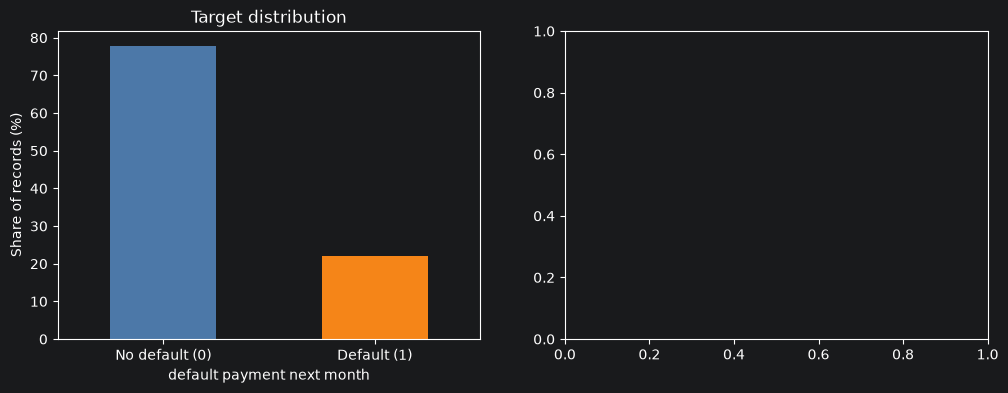

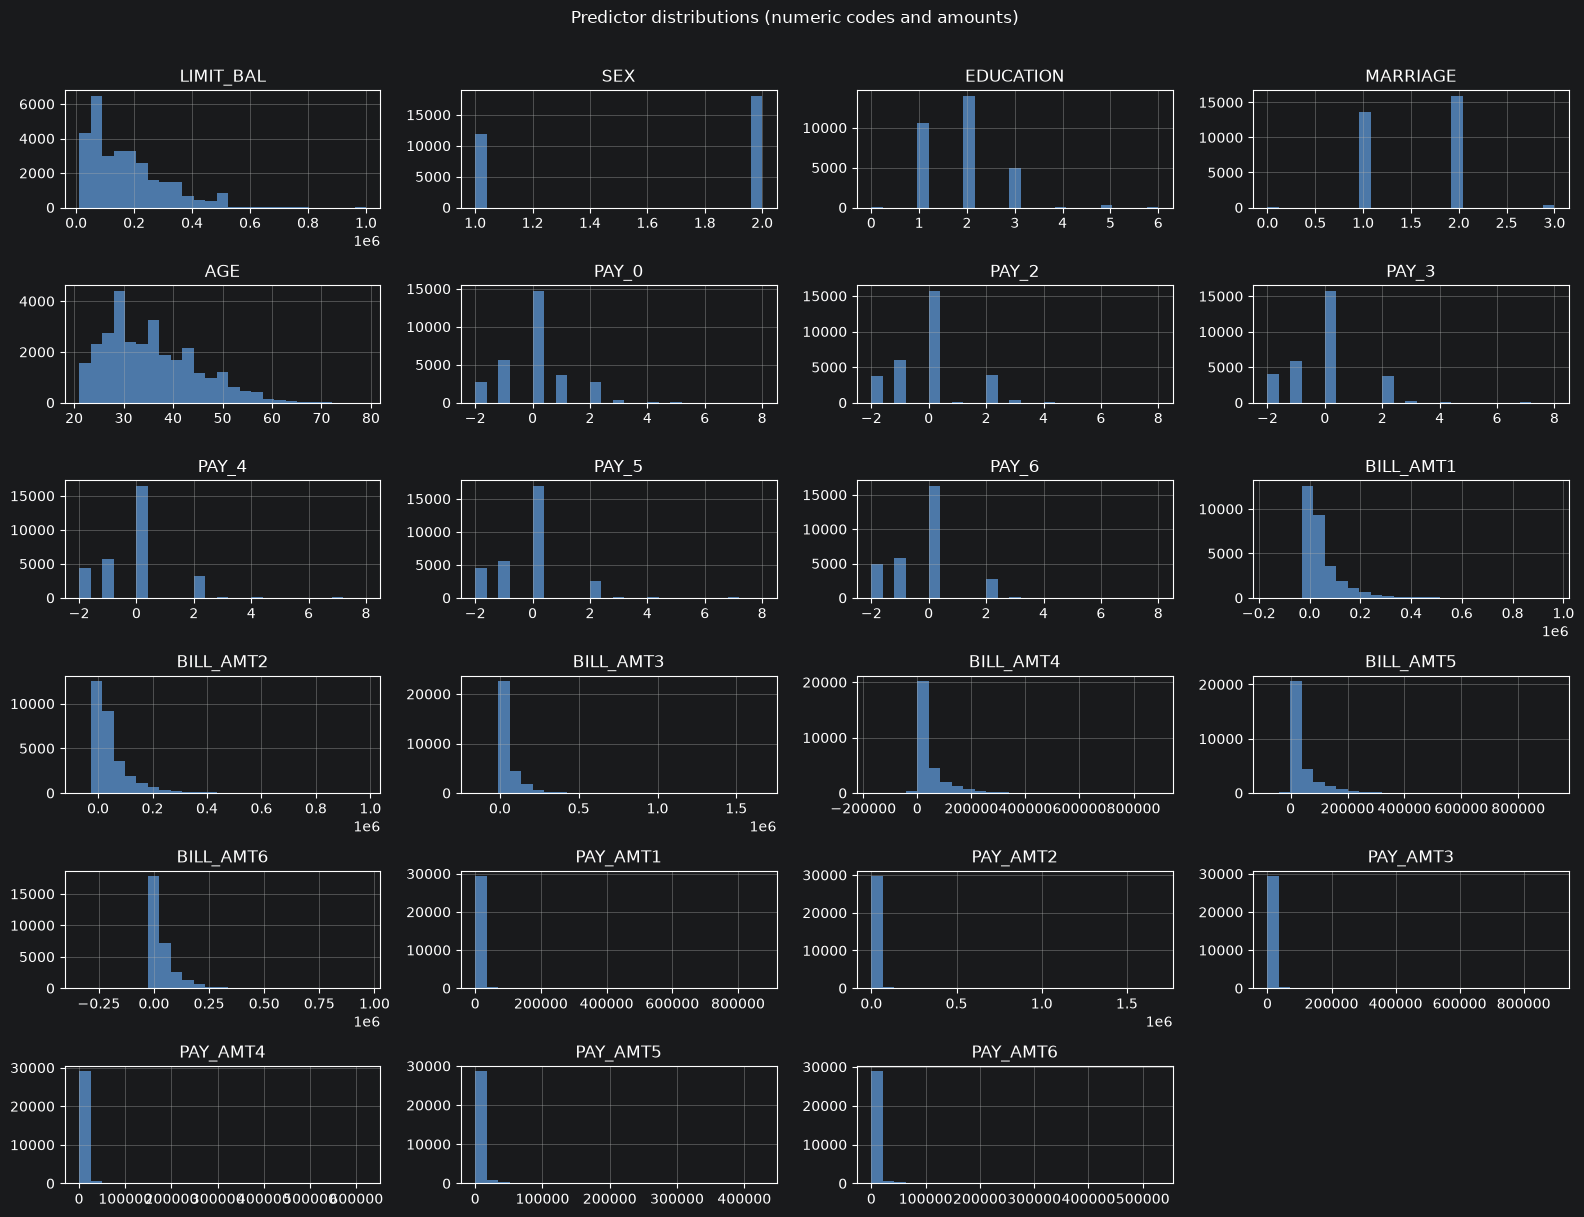

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_share.plot(kind="bar", ax=axes[0], color=["#4C78A8", "#F58518"])
axes[0].set_title("Target distribution")
axes[0].set_ylabel("Share of records (%)")
axes[0].tick_params(axis="x", rotation=0)
X.hist(bins=25, figsize=(16, 12), layout=(6, 4), color="#4C78A8")
plt.suptitle("Predictor distributions (numeric codes and amounts)", y=1.01)
plt.tight_layout()
plt.show()

### Week 1 checkpoint

The workbook has been loaded from the project data folder, the target has been identified, and the initial schema, target balance, missingness and distributions have been inspected. Before submission, add the group members and the real division of work above. The public dataset has a clear binary label and financial-risk relevance; its historical, single-population nature is a key limitation.

## Week 2 — Data preparation and baseline

We exclude identifiers, keep the target separate, and create stratified 60/20/20 training, validation and test sets. The test set is held back for Week 4. Median imputation and scaling are fitted inside each model pipeline; nominal fields are one-hot encoded. This prevents preprocessing leakage during cross-validation.

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, classification_report, ConfusionMatrixDisplay, precision_recall_curve, RocCurveDisplay)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape}, default rate={y_train.mean():.3f}")
print(f"Validation: {X_valid.shape}, default rate={y_valid.mean():.3f}")
print(f"Test (kept untouched until Week 4): {X_test.shape}, default rate={y_test.mean():.3f}")

nominal_names = {"sex", "education", "marriage"}
nominal_columns = [c for c in X.columns if normalize_name(c) in nominal_names]
numeric_columns = [c for c in X.columns if c not in nominal_columns]
numeric_preprocessor = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
nominal_preprocessor = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("numeric", numeric_preprocessor, numeric_columns), ("nominal", nominal_preprocessor, nominal_columns)], remainder="drop")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (18000, 23), default rate=0.221
Validation: (6000, 23), default rate=0.221
Test (kept untouched until Week 4): (6000, 23), default rate=0.221


In [6]:
scoring = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy", "roc_auc": "roc_auc", "average_precision": "average_precision"}
dummy_model = Pipeline([("preprocess", preprocessor), ("classifier", DummyClassifier(strategy="prior"))])
baseline_model = Pipeline([("preprocess", preprocessor), ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
baseline_cv_rows = []
for name, estimator in [("Dummy prior", dummy_model), ("Logistic regression", baseline_model)]:
    scores = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    baseline_cv_rows.append({"model": name, **{metric: scores[f"test_{metric}"].mean() for metric in scoring}})
    print(f"{name}: 5-fold CV complete")
display(pd.DataFrame(baseline_cv_rows).set_index("model").round(4))

Dummy prior: 5-fold CV complete
Logistic regression: 5-fold CV complete


,accuracy,balanced_accuracy,roc_auc,average_precision
model,,,,
Dummy prior,0.7788,0.5000,0.5000,0.2212
Logistic regression,0.8129,0.6139,0.7269,0.5095


In [7]:
baseline_model.fit(X_train, y_train)
y_valid_proba_baseline = baseline_model.predict_proba(X_valid)[:, 1]
y_valid_pred_baseline = (y_valid_proba_baseline >= 0.50).astype(int)

def classification_metrics(y_true, y_pred, y_proba):
    return {"accuracy": accuracy_score(y_true, y_pred), "balanced_accuracy": balanced_accuracy_score(y_true, y_pred), "precision": precision_score(y_true, y_pred, zero_division=0), "recall": recall_score(y_true, y_pred, zero_division=0), "f1": f1_score(y_true, y_pred, zero_division=0), "roc_auc": roc_auc_score(y_true, y_proba), "average_precision": average_precision_score(y_true, y_proba)}

week2_baseline_metrics = classification_metrics(y_valid, y_valid_pred_baseline, y_valid_proba_baseline)
display(pd.Series(week2_baseline_metrics, name="validation score").to_frame().round(4))
print(classification_report(y_valid, y_valid_pred_baseline, target_names=["No default", "Default"], zero_division=0))

,validation score
accuracy,0.8043
balanced_accuracy,0.5984
precision,0.6681
recall,0.2291
f1,0.3412
roc_auc,0.7046
average_precision,0.4795


              precision    recall  f1-score   support

  No default       0.82      0.97      0.89      4673
     Default       0.67      0.23      0.34      1327

    accuracy                           0.80      6000
   macro avg       0.74      0.60      0.61      6000
weighted avg       0.78      0.80      0.76      6000



### Baseline interpretation

The DummyClassifier is a reference that uses only the training-set class prevalence. Logistic regression is the first meaningful model. We report precision, recall, F1, balanced accuracy and average precision because the default class is less common; ROC-AUC is a complementary ranking metric. The 0.50 threshold here is only a baseline convention, not a final business threshold.

## Week 3 — Model development and experimentation

We compare three model families using training data only: logistic regression, logistic regression with mutual-information feature selection, and random forest. Hyperparameters and feature selection are inside GridSearchCV, so each fold fits its own preprocessing and selector. Average precision is the primary tuning score because it focuses on ranking the minority default class.

In [8]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

logistic_search = GridSearchCV(
    estimator=Pipeline([("preprocess", preprocessor), ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
    param_grid={"classifier__C": [0.1, 1.0, 10.0], "classifier__class_weight": [None, "balanced"]},
    scoring="average_precision", cv=cv, n_jobs=-1, refit=True)
selection_search = GridSearchCV(
    estimator=Pipeline([("preprocess", preprocessor), ("selection", SelectKBest(score_func=mutual_info_classif)), ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
    param_grid={"selection__k": [15, 25, 35], "classifier__C": [0.1, 1.0], "classifier__class_weight": [None, "balanced"]},
    scoring="average_precision", cv=cv, n_jobs=-1, refit=True)
forest_search = GridSearchCV(
    estimator=Pipeline([("preprocess", preprocessor), ("classifier", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1))]),
    param_grid={"classifier__max_depth": [12, None], "classifier__min_samples_leaf": [2, 8], "classifier__class_weight": [None, "balanced_subsample"]},
    scoring="average_precision", cv=cv, n_jobs=-1, refit=True)
searches = {"Tuned logistic regression": logistic_search, "Feature-selected logistic regression": selection_search, "Random forest": forest_search}
for name, search in searches.items():
    search.fit(X_train, y_train)
    print(f"{name}: best CV average precision={search.best_score_:.4f}; params={search.best_params_}")

Tuned logistic regression: best CV average precision=0.5095; params={'classifier__C': 1.0, 'classifier__class_weight': None}


/Users/duale/Credit_Default_Prediction_ML/.venv/lib/python3.15/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=35 is greater than n_features=33. All the features will be returned.
  warnings.warn(
/Users/duale/Credit_Default_Prediction_ML/.venv/lib/python3.15/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=35 is greater than n_features=33. All the features will be returned.
  warnings.warn(
/Users/duale/Credit_Default_Prediction_ML/.venv/lib/python3.15/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=35 is greater than n_features=33. All the features will be returned.
  warnings.warn(
/Users/duale/Credit_Default_Prediction_ML/.venv/lib/python3.15/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=35 is greater than n_features=33. All the features will be returned.
  warnings.warn(
/Users/duale/Credit_Default_Prediction_ML/.venv/lib/python3.15/s

Feature-selected logistic regression: best CV average precision=0.5095; params={'classifier__C': 1.0, 'classifier__class_weight': None, 'selection__k': 35}
Random forest: best CV average precision=0.5553; params={'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__min_samples_leaf': 8}


In [9]:
week3_cv_results = pd.DataFrame([{"model": name, "best_cv_average_precision": search.best_score_, "best_parameters": str(search.best_params_)} for name, search in searches.items()]).sort_values("best_cv_average_precision", ascending=False)
display(week3_cv_results.round(4))
week3_validation_rows = []
week3_validation_scores = {}
for name, search in searches.items():
    validation_proba = search.best_estimator_.predict_proba(X_valid)[:, 1]
    week3_validation_scores[name] = validation_proba
    row = classification_metrics(y_valid, (validation_proba >= 0.50).astype(int), validation_proba)
    row["model"] = name
    week3_validation_rows.append(row)
week3_validation = pd.DataFrame(week3_validation_rows).set_index("model")
display(week3_validation.round(4))

,model,best_cv_average_precision,best_parameters
2,Random forest,0.5553,"{'classifier__class_weight': None, 'classifier..."
0,Tuned logistic regression,0.5095,"{'classifier__C': 1.0, 'classifier__class_weig..."
1,Feature-selected logistic regression,0.5095,"{'classifier__C': 1.0, 'classifier__class_weig..."


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
model,,,,,,,
Tuned logistic regression,0.8043,0.5984,0.6681,0.2291,0.3412,0.7046,0.4795
Feature-selected logistic regression,0.8043,0.5984,0.6681,0.2291,0.3412,0.7046,0.4795
Random forest,0.8115,0.6362,0.6489,0.3218,0.4302,0.7751,0.5322


### Error analysis and limitations

Compare validation precision and recall rather than selecting by accuracy alone. False negatives are clients who later default but are not flagged; false positives are clients flagged despite no recorded default. Their relative costs depend on the lender and cannot be inferred from this dataset. The random split measures performance within this historical dataset, not performance over time or at another institution. Feature selection is performed inside cross-validation to avoid leaking validation-fold labels.

## Week 4 — Final evaluation and presentation

We choose the model using validation average precision, set a threshold using validation labels only, refit the chosen model on training plus validation data, and evaluate once on the untouched test set. The selected threshold maximizes validation F1 for a transparent demonstration; a real credit-risk deployment would require a cost-sensitive threshold and governance review.

In [10]:
selected_model_name = max(week3_validation_scores, key=lambda name: average_precision_score(y_valid, week3_validation_scores[name]))
selected_search = searches[selected_model_name]
validation_proba = week3_validation_scores[selected_model_name]
precision_values, recall_values, thresholds = precision_recall_curve(y_valid, validation_proba)
if len(thresholds) == 0:
    selected_threshold = 0.50
else:
    f1_values = 2 * precision_values[:-1] * recall_values[:-1] / np.maximum(precision_values[:-1] + recall_values[:-1], 1e-12)
    selected_threshold = float(thresholds[int(np.argmax(f1_values))])
print("Selected model:", selected_model_name)
print("Validation average precision:", round(average_precision_score(y_valid, validation_proba), 4))
print("Validation-selected threshold (maximizes F1):", round(selected_threshold, 4))

X_train_valid = pd.concat([X_train, X_valid], axis=0)
y_train_valid = pd.concat([y_train, y_valid], axis=0)
final_model = selected_search.best_estimator_
final_model.fit(X_train_valid, y_train_valid)
y_test_proba = final_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_proba >= selected_threshold).astype(int)
final_test_metrics = classification_metrics(y_test, y_test_pred, y_test_proba)
print("\nFinal held-out test results")
display(pd.Series(final_test_metrics, name="test score").to_frame().round(4))
print(classification_report(y_test, y_test_pred, target_names=["No default", "Default"], zero_division=0))

Selected model: Random forest
Validation average precision: 0.5322
Validation-selected threshold (maximizes F1): 0.323

Final held-out test results


,test score
accuracy,0.8040
balanced_accuracy,0.7118
precision,0.5581
recall,0.5463
f1,0.5522
roc_auc,0.7859
average_precision,0.5695


              precision    recall  f1-score   support

  No default       0.87      0.88      0.87      4673
     Default       0.56      0.55      0.55      1327

    accuracy                           0.80      6000
   macro avg       0.72      0.71      0.71      6000
weighted avg       0.80      0.80      0.80      6000



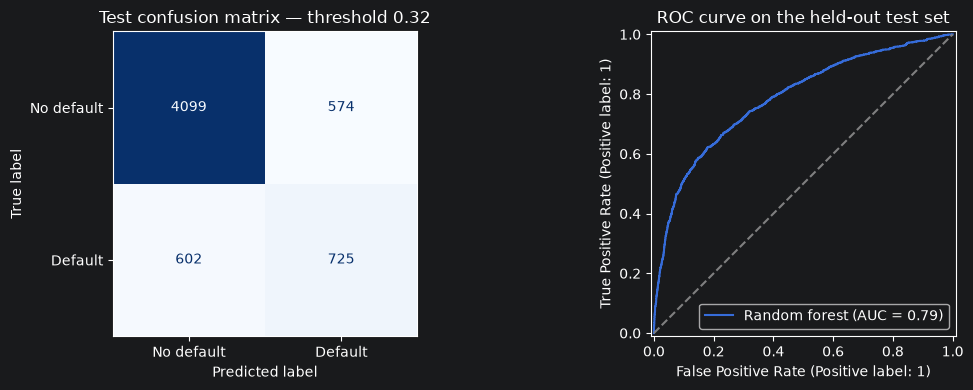

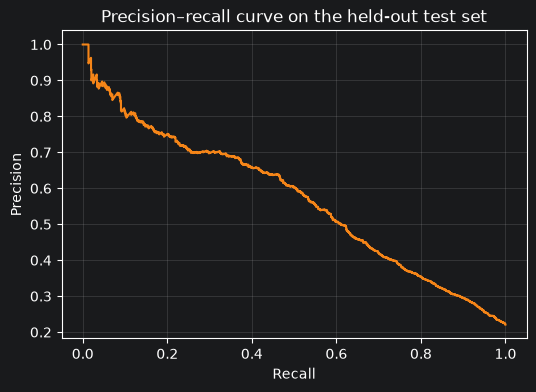

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, display_labels=["No default", "Default"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"Test confusion matrix — threshold {selected_threshold:.2f}")
RocCurveDisplay.from_predictions(y_test, y_test_proba, ax=axes[1], name=selected_model_name)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random ranking")
axes[1].set_title("ROC curve on the held-out test set")
plt.tight_layout()
plt.show()

precision_test, recall_test, _ = precision_recall_curve(y_test, y_test_proba)
plt.figure(figsize=(6, 4))
plt.plot(recall_test, precision_test, color="#F58518")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–recall curve on the held-out test set")
plt.grid(alpha=0.25)
plt.show()

### Interpretation, limitations and possible improvements

- **Interpretation:** report the selected model, validation-selected threshold and held-out test metrics above. Explain the precision–recall trade-off in terms of false alarms and missed defaults.
- **Limitations:** the data are historical, from one population, and may not represent present-day borrowers. A random split does not establish temporal or external validity. Recorded demographic and repayment variables can encode sensitive or proxy information. The dataset does not provide the business costs needed to define an operational threshold.
- **Possible improvements:** evaluate fairness and error rates across relevant groups; use a time-based or external validation set if available; calibrate predicted probabilities; choose a threshold from explicit business costs; compare additional boosting models; and monitor drift before any real deployment.
- **Responsible use:** this academic model is a decision-support experiment only. It should not be used to approve, reject or price real credit without legal, fairness, privacy, calibration and human-governance review.

### Final presentation outline

1. **Problem:** predict next-month credit-card default; explain why early risk estimation matters.
2. **Data:** UCI Default of Credit Card Clients; describe the verified row/feature counts, target balance and quality checks from Week 1.
3. **Method:** leakage-safe stratified split; Dummy and logistic baselines; tuned logistic, mutual-information feature selection and random forest.
4. **Results:** show the Week 3 comparison and Week 4 test metrics, confusion matrix and precision–recall curve. State the validation-selected threshold and its F1 objective.
5. **Conclusion:** summarize whether the model improves on baseline, explain errors and limitations, and propose fairness and temporal/external validation.

**Before presenting:** insert the group members and task allocation; replace bracketed team information; rerun the notebook from top to bottom with the project's Python environment so the tables and figures reflect the current data file.
